**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/17_tolerance_intervals_and_decision_sizing.ipynb)** | **🐍 [Python](../python/17_tolerance_intervals_and_decision_sizing.ipynb)** | **⬅️ [Prev: Ch 16: Decision Theory & Loss Functions](16_bayesian_decision_theory_and_predictive_checks.ipynb)** | **➡️ [Next: Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)**

*🧭 Part IV: Dynamic Systems, Decision Theory & Predictive Guarantees — Chapter 17 of 22*

---

# Chapter 17: Frequentist vs. Bayesian Tolerance Intervals & Decision Sizing
### *From the Flaw of Averages to Prediction and Tolerance Intervals*

---

## 1. Problem Framing: The Engineering & Clinical Challenge

Suppose you are the chief operations engineer for a regional healthcare system
designing standard patient beds for a new 500-bed hospital wing.

You measure a calibration sample of $n = 50$ adult patient heights (the exact
dataset from **Chapters 5 & 6** of the Bayesian Inference curriculum):
- **Sample Size**: $n = 50$
- **Sample Mean ($\bar{y}$)**: $172.21\text{ cm}$
- **Sample Standard Deviation ($s$)**: $9.21\text{ cm}$

The hospital board specifies an engineering requirement:
> *"How long must our beds be so that we have a rigorous statistical
> guarantee that incoming patients will sleep comfortably without hanging
> over the mattress edge?"*

In this notebook, we systematically compare **5 distinct statistical paradigms**
to solve this problem:
1. **The Administrative Trap (The Flaw of Averages)**: Sizing based on the mean
   $\mu$ alone.
2. **The Naive Frequentist Plug-In Rule**: $\bar{y} + z_{0.99} \cdot s$.
3. **Proper Frequentist Tool #1 (The Prediction Interval)**: Guarantees for
   the *very next patient*.
4. **Proper Frequentist Tool #2 (The Tolerance Interval / ISO 16269-6)**:
   Guarantees for the *entire population*.
5. **The Bayesian Posterior Predictive Solution & Asymmetric Loss
   Minimization**: Integrating prior domain knowledge and real-world financial
   penalties.


In [1]:
# Load statistical packages and generate the calibration dataset
suppressPackageStartupMessages({
  library(MASS)
})

# Generate the identical n = 50 dataset from Chapters 5 & 6
set.seed(42)
n <- 50
heights <- rnorm(n, mean = 172.5, sd = 8.0)

y_bar <- mean(heights)
s     <- sd(heights)

cat(sprintf("Dataset Initialized: n = %d\n", n))
cat(sprintf("Sample Mean (y_bar): %.2f cm\n", y_bar))
cat(sprintf("Sample Std  (s):     %.2f cm\n", s))


Dataset Initialized: n = 50


Sample Mean (y_bar): 172.21 cm


Sample Std  (s):     9.21 cm


---

## 2. Method 0: The Administrative Trap (The "Flaw of Averages")

In real-world procurement and facility management, non-technical committees
routinely fall into the **Flaw of Averages** (popularized by Stanford professor
Sam Savage):
- A hospital committee reads the report: *"The average adult height is
  $172.2\text{ cm}$."*
- They reason: *"If we buy $180\text{ cm}$ beds, we have a generous safety
  buffer of $+7.8\text{ cm}$ above the average patient. That must be plenty
  safe!"*

### The Historical Warning: The 1950s Air Force Cockpit Disaster
In the 1950s, the U.S. Air Force experienced puzzlingly high crash rates in
high-performance jet fighters. The cockpits had been engineered to fit the
"average pilot," calculated from measurements of over 4,000 pilots across 10
physical dimensions (sitting height, chest circumference, sleeve length, etc.).

When researcher **Gilbert Daniels** analyzed the data to determine how many of
the 4,000 pilots were within the middle 30% ("average") on all 10 dimensions,
the result was stunning: **ZERO**.
By designing for the average pilot, the Air Force had engineered cockpits that
**properly fit no one**.

Let us quantify the hospital's operational failure rate if it builds naive
$180\text{ cm}$ beds:


In [2]:
# Evaluate overflow risk for naive 180 cm bed in Base R
prob_fail_180 <- 1.0 - pnorm(180.0, mean = y_bar, sd = s)

cat("=== Method 0: Naive Mean Bed (180 cm) ===\n")
cat(sprintf("Patient Overflow Probability P(Y > 180 cm): %.1f%%\n",
            prob_fail_180 * 100))
cat(sprintf("Impact: 1 in every %d patients will hang off the mattress!\n",
            round(1 / prob_fail_180)))


=== Method 0: Naive Mean Bed (180 cm) ===


Patient Overflow Probability P(Y > 180 cm): 19.9%


Impact: 1 in every 5 patients will hang off the mattress!


---

## 3. Method 1: Naive Frequentist Plug-In Rule ($\bar{y} + z_{0.99} \cdot s$)

A savvy engineer knows not to look at the mean alone and immediately factors in
the standard deviation:
$$\text{Bed Length}_{\text{Plug-In}} = \bar{y} + z_{0.99} \times s$$
For a standard Normal distribution, the 99th percentile cutoff is
$z_{0.99} = \text{qnorm}(0.99) \approx 2.3263$.

### Why This is Overconfident (The Plug-In Fallacy):
This formula "plugs in" the sample estimates $(\bar{y}, s)$ as if they were
the true, eternal parameters of nature $(\mu, \sigma)$ with zero measurement
error.
- But $\bar{y}$ was calculated from only **$n = 50$ people**
  ($\text{SE}(\mu) \approx 1.30\text{ cm}$).
- $s$ is also a noisy sample estimate.
- Treating sample estimates as fixed truth underestimates the true spread of
  future data.


In [3]:
# Method 1: Plug-in rule using qnorm()
z_99 <- qnorm(0.99)
bed_plugin_99 <- y_bar + z_99 * s

cat("=== Method 1: Naive Frequentist Plug-In ===\n")
cat(sprintf("z-multiplier for 99%%: %.4f\n", z_99))
cat(sprintf("Plug-In Bed Length:   %.2f cm\n", bed_plugin_99))


=== Method 1: Naive Frequentist Plug-In ===


z-multiplier for 99%: 2.3263


Plug-In Bed Length:   193.64 cm


---

## 4. Method 2: Frequentist Prediction Bound (Next Single Patient)

If the hospital's clinical question is:
> *"We want a $99\%$ probability that the **very next patient** admitted to
> the hospital will fit comfortably in the bed."*

The proper frequentist tool is a **One-Sided Upper Prediction Bound**.

### Mathematical Derivation:
When predicting an unobserved future patient
$Y_{\text{new}} \sim \text{Normal}(\mu, \sigma^2)$, the difference
between the sample mean $\bar{Y}$ and $Y_{\text{new}}$ has variance:
$$\text{Var}(Y_{\text{new}} - \bar{Y}) = \text{Var}(Y_{\text{new}}) + \text{Var}(\bar{Y}) = \sigma^2 + \frac{\sigma^2}{n} = \sigma^2 \left(1 + \frac{1}{n}\right)$$

Because the true standard deviation $\sigma$ is unknown and estimated by $s$,
the standardized pivot follows a **Student's $t$-distribution** with $n - 1$
degrees of freedom:
$$T = \frac{Y_{\text{new}} - \bar{Y}}{s \sqrt{1 + \frac{1}{n}}} \sim t_{n-1}$$

### The Prediction Formula:
$$\text{Bed Length}_{\text{Pred}} = \bar{y} + t_{n-1, \, 0.99} \times s \sqrt{1 + \frac{1}{n}}$$

Notice the two corrections over the naive plug-in:
1. **$t_{n-1} > z$**: The Student's $t$ critical value ($2.4049$) is larger than
   $z$ ($2.3263$) to account for uncertainty in estimating $\sigma$.
2. **$\sqrt{1 + 1/n} > 1$**: Incorporates the sampling error of the mean
   $\bar{y}$.


In [4]:
# Method 2: One-sided Student-t prediction bound
t_99 <- qt(0.99, df = n - 1)
inflation_factor <- sqrt(1.0 + 1.0 / n)
bed_pred_99 <- y_bar + t_99 * s * inflation_factor

cat("=== Method 2: Frequentist Prediction Bound (Next Single Patient) ===\n")
cat(sprintf("t critical value (df=%d): %.4f  (vs. z = %.4f)\n",
            n - 1, t_99, z_99))
cat(sprintf("Sampling inflation sqrt(1 + 1/n): %.4f\n", inflation_factor))
cat(sprintf("Prediction Bed Length:     %.2f cm\n", bed_pred_99))
cat(sprintf("Difference vs Plug-In:     +%.2f cm (Accounts for sample noise)\n",
            bed_pred_99 - bed_plugin_99))


=== Method 2: Frequentist Prediction Bound (Next Single Patient) ===


t critical value (df=49): 2.4049  (vs. z = 2.3263)


Sampling inflation sqrt(1 + 1/n): 1.0100


Prediction Bed Length:     194.59 cm


Difference vs Plug-In:     +0.94 cm (Accounts for sample noise)


---

## 5. Method 3: Upper Tolerance Limits (ISO 16269-6 / Industrial Standard)

A hospital does not manufacture a bed for just *one* patient; it builds
hundreds of beds to serve **thousands of patients over a 15-year lifecycle**.

The executive clinical board demands an industrial-grade reliability guarantee:
> *"We want **$95\%$ confidence** that **at least $99\%$ of the entire
> patient population** will fit in our standard beds."*

In industrial statistics and quality engineering, this is called a
**$(p, 1-\gamma)$ Upper Tolerance Limit** ($p = 0.99$, confidence
$1-\gamma = 0.95$).

### Mathematical Derivation via the Non-Central $t$-Distribution:
We seek a tolerance factor $k$ such that:
$$P\left( P(Y \le \bar{y} + k \cdot s) \ge p \right) = 1 - \gamma$$
This condition requires finding the quantile of a **Non-Central
$t$-Distribution** with non-centrality parameter $\delta = z_p \sqrt{n}$:
$$k = \frac{t_{n-1, \, 1-\gamma, \, \delta}}{\sqrt{n}} = \frac{\text{qt}(1-\gamma, \,\text{df}=n-1, \,\text{ncp}=\delta)}{\sqrt{n}}$$

### The Tolerance Formula:
$$\text{Bed Length}_{\text{Tol}} = \bar{y} + k \times s$$


In [5]:
# Method 3: ISO 16269-6 Tolerance Limit via qt(..., ncp=...)
p_coverage <- 0.99
gamma_conf <- 0.95

delta <- qnorm(p_coverage) * sqrt(n)
t_nct <- qt(gamma_conf, df = n - 1, ncp = delta)
k_tol <- t_nct / sqrt(n)

bed_tol_99 <- y_bar + k_tol * s

cat("=== Method 3: Frequentist Tolerance Limit (Entire Population) ===\n")
cat(sprintf("Non-centrality parameter (delta): %.4f\n", delta))
cat(sprintf("Tolerance Factor (k):              %.4f  (vs. z = %.4f)\n",
            k_tol, z_99))
cat(sprintf("ISO Tolerance Bed Length:          %.2f cm\n", bed_tol_99))
cat(sprintf("Difference vs Plug-In:             +%.2f cm\n",
            bed_tol_99 - bed_plugin_99))
cat(sprintf("Difference vs Prediction Bound:    +%.2f cm\n",
            bed_tol_99 - bed_pred_99))


=== Method 3: Frequentist Tolerance Limit (Entire Population) ===


Non-centrality parameter (delta): 16.4498


Tolerance Factor (k):              2.8624  (vs. z = 2.3263)


ISO Tolerance Bed Length:          198.58 cm


Difference vs Plug-In:             +4.94 cm


Difference vs Prediction Bound:    +3.99 cm


---

## 6. Method 4: The Bayesian Posterior Predictive Solution

In the Bayesian paradigm:
- Parameters $(\mu, \sigma)$ are not fixed unknown constants; they are
  described by a **joint posterior distribution** $p(\mu, \sigma \mid y)$.
- Predictions for new patients do not rely on single point estimates or
  complicated non-central distributions.
- Instead, we simulate the **Posterior Predictive Distribution**:
  $$p(y_{\text{new}} \mid y) = \iint p(y_{\text{new}} \mid \mu, \sigma) \, p(\mu, \sigma \mid y) \, d\mu \, d\sigma$$

### The 2-Stage Simulation Cascade:
1. Draw parameter vectors $(\mu^{(s)}, \sigma^{(s)})$ from the posterior
   distribution (incorporating parameter uncertainty and covariance).
2. For each draw, simulate a future patient
   $y_{\text{new}}^{(s)} \sim \text{Normal}(\mu^{(s)}, \sigma^{(s)})$
   (incorporating observation noise).
3. The empirical $99^{\text{th}}$ percentile of $y_{\text{new}}$ directly
   yields the Bayesian bed length!

We specify domain priors:
$$\mu \sim \text{Normal}(178, \, 20)$$
$$\sigma \sim \text{Uniform}(0, \, 50)$$
$$y_i \sim \text{Normal}(\mu, \, \sigma)$$


In [6]:
# 1. Define Negative Log-Posterior Function in Base R
neg_log_posterior <- function(params) {
  mu    <- params[1]
  sigma <- params[2]
  if (sigma <= 0.0 || sigma >= 50.0) return(1e10)
  
  log_prior_mu    <- dnorm(mu, mean = 178.0, sd = 20.0, log = TRUE)
  log_prior_sigma <- dunif(sigma, min = 0.0, max = 50.0, log = TRUE)
  log_lik         <- sum(dnorm(heights, mean = mu, sd = sigma, log = TRUE))
  
  return(-(log_prior_mu + log_prior_sigma + log_lik))
}

# 2. Optimize to find MAP and Numerical Hessian
opt <- optim(
  par     = c(y_bar, s),
  fn      = neg_log_posterior,
  hessian = TRUE,
  method  = "BFGS"
)

map_estimates <- opt$par
H <- opt$hessian
vcov_matrix <- solve(H)

# 3. 2-Stage Posterior Predictive Simulation (10,000 future individuals)
set.seed(42)
quap_draws <- MASS::mvrnorm(n = 10000, mu = map_estimates, Sigma = vcov_matrix)
pred_heights <- rnorm(10000, mean = quap_draws[, 1], sd = quap_draws[, 2])

# Extract empirical quantiles
bed_bayes_95  <- quantile(pred_heights, 0.95)
bed_bayes_99  <- quantile(pred_heights, 0.99)
bed_bayes_999 <- quantile(pred_heights, 0.999)

cat("=== Method 4: Bayesian Posterior Predictive Distribution ===\n")
cat(sprintf("MAP Estimates: mu = %.2f cm, sigma = %.2f cm\n",
            map_estimates[1], map_estimates[2]))
cat(sprintf("Bayesian 95%% Spec:   %.2f cm\n", bed_bayes_95))
cat(sprintf("Bayesian 99%% Spec:   %.2f cm\n", bed_bayes_99))
cat(sprintf("Bayesian 99.9%% Spec: %.2f cm\n", bed_bayes_999))


=== Method 4: Bayesian Posterior Predictive Distribution ===


MAP Estimates: mu = 172.24 cm, sigma = 9.12 cm


Bayesian 95% Spec:   187.78 cm


Bayesian 99% Spec:   193.79 cm


Bayesian 99.9% Spec: 201.60 cm


---

## 7. Method 5: Beyond Arbitrary Percentiles — Bayesian Decision Theory

In real-world engineering, asking for "99% coverage" is fundamentally arbitrary:
- Why not $98.5\%$? Why not $99.9\%$?

**The real world has an asymmetric cost structure**:
- **Building a bed $1\text{ cm}$ too long** ($L > y_{\text{new}}$): Incurs a
  small material & floor footprint penalty:
  $$C_{\text{over}} = 15\text{ USD/cm}$$
- **Building a bed $1\text{ cm}$ too short** ($L < y_{\text{new}}$): Incurs
  a severe clinical & legal penalty (patient transfers, foot ulcers, liability):
  $$C_{\text{under}} = 150\text{ USD/cm}$$

### Mathematical Derivation of Optimal Bed Length:
The economic loss for building a bed of length $L$ for a patient of height $y$
is the **asymmetric linear loss** (pinball / check loss):
$$\text{Loss}(L, y) = \begin{cases} C_{\text{under}} \cdot (y - L) & \text{if } y > L \quad (\text{Patient too tall}) \\ C_{\text{over}} \cdot (L - y) & \text{if } y \le L \quad (\text{Wasted mattress length}) \end{cases}$$

Under **Bayesian Decision Theory**, the optimal bed length $L^*$ minimizes the
**Posterior Expected Loss**:
$$L^* = \arg\min_L \mathbb{E}_{y_{\text{new}} \mid y} \Big[ \text{Loss}(L, y_{\text{new}}) \Big]$$

Differentiating with respect to $L$ reveals the famous **Newsvendor /
Quantile Rule**:
$$P(y_{\text{new}} \le L^*) = \frac{C_{\text{under}}}{C_{\text{under}} + C_{\text{over}}} = \frac{150}{150 + 15} = \frac{150}{165} \approx \mathbf{90.91\%}$$

The mathematically optimal bed length is precisely the
**$90.91^{\text{th}}$ percentile** of the posterior predictive distribution!


In [7]:
# 1. Define Cost Parameters
c_over  <- 15.0   # $15 per cm of wasted space/material
c_under <- 150.0  # $150 per cm of patient overflow

# 2. Optimal Theoretical Quantile
tau_star <- c_under / (c_under + c_over)
optimal_bed_length <- as.numeric(quantile(pred_heights, tau_star))

# 3. Empirically evaluate expected cost across candidate bed lengths
candidate_lengths <- seq(170, 205, length.out = 150)
expected_losses <- sapply(candidate_lengths, function(l_cand) {
  diff <- pred_heights - l_cand
  loss <- ifelse(diff > 0, diff * c_under, -diff * c_over)
  mean(loss)
})

emp_min_idx <- which.min(expected_losses)

cat("=== Method 5: Bayesian Decision Theory (Optimal Economic Sizing) ===\n")
cat(sprintf("Underlength Cost: $%.2f/cm vs. Overlength Cost: $%.2f/cm\n",
            c_under, c_over))
cat(sprintf("Optimal Quantile Ratio tau*: %.2f%%\n", tau_star * 100))
cat(sprintf("Analytic Optimal Bed Length: %.2f cm\n", optimal_bed_length))
cat(sprintf("Empirical Grid Minimum:      %.2f cm (Min Expected Cost: $%.2f / patient)\n",
            candidate_lengths[emp_min_idx], expected_losses[emp_min_idx]))


=== Method 5: Bayesian Decision Theory (Optimal Economic Sizing) ===


Underlength Cost: $150.00/cm vs. Overlength Cost: $15.00/cm


Optimal Quantile Ratio tau*: 90.91%


Analytic Optimal Bed Length: 184.75 cm


Empirical Grid Minimum:      184.80 cm (Min Expected Cost: $252.54 / patient)


---

## 8. Interactive Visual Dashboard: Comparing All Paradigms

Let us overlay all 5 decision cutoffs and inspect the economic cost curve
side-by-side in Base R:


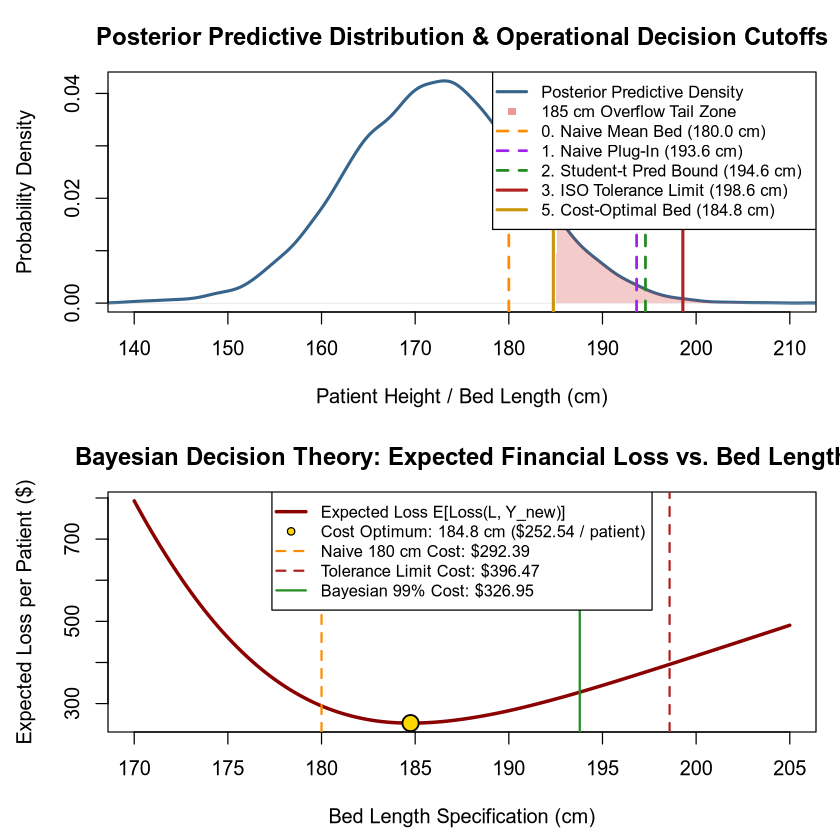

In [8]:
# 2-Panel Decision Sizing Dashboard in Base R
par(mfrow = c(2, 1), mar = c(4.5, 4.5, 3, 1))

# ==================== Plot 1: Posterior Predictive Density ====================
dens <- density(pred_heights, n = 512)
plot(dens,
     main = "Posterior Predictive Distribution & Operational Decision Cutoffs",
     xlab = "Patient Height / Bed Length (cm)", ylab = "Probability Density",
     col = "steelblue4", lwd = 2.5, font.main = 2, xlim = c(140, 210))

# Shade tail risk zones (> 185 cm)
tail_idx <- which(dens$x >= 185.0)
polygon(c(185.0, dens$x[tail_idx], max(dens$x[tail_idx])),
        c(0, dens$y[tail_idx], 0),
        col = rgb(0.85, 0.2, 0.2, 0.25), border = NA)

# Draw decision cutoffs
abline(v = 180.0, col = "darkorange", lwd = 2.2, lty = 2)
abline(v = bed_plugin_99, col = "purple", lwd = 2.2, lty = 2)
abline(v = bed_pred_99, col = "forestgreen", lwd = 2.2, lty = 2)
abline(v = bed_tol_99, col = "firebrick", lwd = 2.5, lty = 1)
abline(v = optimal_bed_length, col = "darkgoldenrod3", lwd = 2.5, lty = 1)

legend("topright",
       legend = c("Posterior Predictive Density",
                  "185 cm Overflow Tail Zone",
                  "0. Naive Mean Bed (180.0 cm)",
                  sprintf("1. Naive Plug-In (%.1f cm)", bed_plugin_99),
                  sprintf("2. Student-t Pred Bound (%.1f cm)", bed_pred_99),
                  sprintf("3. ISO Tolerance Limit (%.1f cm)", bed_tol_99),
                  sprintf("5. Cost-Optimal Bed (%.1f cm)", optimal_bed_length)),
       col = c("steelblue4", rgb(0.85, 0.2, 0.2, 0.5), "darkorange", "purple",
               "forestgreen", "firebrick", "darkgoldenrod3"),
       lty = c(1, NA, 2, 2, 2, 1, 1),
       pch = c(NA, 15, NA, NA, NA, NA, NA),
       lwd = c(2.5, NA, 2.2, 2.2, 2.2, 2.5, 2.5),
       bg = "white", cex = 0.82)

# ==================== Plot 2: Expected Economic Loss Curve ====================
plot(candidate_lengths, expected_losses, type = "l", col = "darkred", lwd = 2.8,
     main = "Bayesian Decision Theory: Expected Financial Loss vs. Bed Length",
     xlab = "Bed Length Specification (cm)",
     ylab = "Expected Loss per Patient ($)", font.main = 2)

# Highlight cost-optimum
points(optimal_bed_length, min(expected_losses), pch = 21, bg = "gold",
       col = "black", cex = 1.8, lwd = 1.5)

# Benchmark vertical lines
naive_cost <- expected_losses[which.min(abs(candidate_lengths - 180.0))]
tol_cost   <- expected_losses[which.min(abs(candidate_lengths - bed_tol_99))]
bayes_cost <- expected_losses[which.min(abs(candidate_lengths - bed_bayes_99))]

abline(v = 180.0, col = "darkorange", lty = 2, lwd = 1.8)
abline(v = bed_tol_99, col = "firebrick", lty = 2, lwd = 1.8)
abline(v = bed_bayes_99, col = "forestgreen", lty = 1, lwd = 1.8)

legend("top",
       legend = c("Expected Loss E[Loss(L, Y_new)]",
                  sprintf("Cost Optimum: %.1f cm ($%.2f / patient)",
                          optimal_bed_length, min(expected_losses)),
                  sprintf("Naive 180 cm Cost: $%.2f", naive_cost),
                  sprintf("Tolerance Limit Cost: $%.2f", tol_cost),
                  sprintf("Bayesian 99%% Cost: $%.2f", bayes_cost)),
       col = c("darkred", "black", "darkorange", "firebrick", "forestgreen"),
       pch = c(NA, 21, NA, NA, NA),
       pt.bg = c(NA, "gold", NA, NA, NA),
       lty = c(1, NA, 2, 2, 1),
       lwd = c(2.8, NA, 1.8, 1.8, 1.8),
       bg = "white", cex = 0.82)

par(mfrow = c(1, 1))


---

## 9. Master Synthesis: The Five Paradigms Side-by-Side

| Method | Statistical Question Answered | Mathematical Formula | Resulting Bed Length | Real World Trade-Off |
| :--- | :--- | :--- | :---: | :--- |
| **0. Naive Mean Buffer** | *"What if everyone is close to average?"* | $\hat{\mu} + 7.8\text{ cm buffer}$ | **$180.00\text{ cm}$** | **$19.9\%$ fail to fit**. The Flaw of Averages causes severe clinical failure. |
| **1. Naive Plug-In** | *"What if our 50-person sample was 100% exact?"* | $\bar{y} + z_{0.99} \cdot s$ | **$193.64\text{ cm}$** | **Overconfident**. Ignores sampling noise in $\bar{y}$ and $s$. |
| **2. Prediction Bound** | *"Will the very next patient fit?"* ($99\%$ confidence) | $\bar{y} + t_{n-1, 0.99} \cdot s \sqrt{1 + 1/n}$ | **$194.59\text{ cm}$** | Exact for 1 upcoming patient; does not guarantee multi-patient population coverage. |
| **3. Tolerance Limit (ISO)** | *"Will $\ge 99\%$ of all patients fit?"* ($95\%$ confidence) | $\bar{y} + k \cdot s$ (via Non-Central $t$) | **$198.58\text{ cm}$** | **Rigorous industrial guarantee**. Longest bed ($198.6\text{ cm}$) to buffer against worst-case sample noise. |
| **4. Bayesian Predictive** | *"What is the 99th percentile given prior + data?"* | $\text{Quantile}_{0.99}(y_{\text{new}})$ | **$193.79\text{ cm}$** | Smoothly integrates prior domain knowledge and full parameter covariance $\mathbf{\Sigma} = \mathbf{H}^{-1}$. |
| **5. Bayesian Decision Theory** | *"What bed length minimizes total operational cost?"* | $\arg\min_L \mathbb{E}[\text{Loss}(L, y_{\text{new}})]$ | **$184.75\text{ cm}$** | Explicitly balances `\$15/cm` material cost against `\$150/cm` overflow liability. |

### 💡 Core Takeaways:
1. **Never use the sample mean alone** for capacity or clearance problems—it
   guarantees high failure rates in the tails.
2. **If you are in a purely frequentist world**:
   - Use a **Prediction Interval** if you care about the *next single
     individual*.
   - Use a **Tolerance Interval (Non-Central $t$)** if you are manufacturing
     products for the *entire population*.
3. **If you are in a Bayesian world**:
   - The **Posterior Predictive Distribution** handles everything cleanly in
     one unified simulation cascade.
   - You can easily layer **Loss Functions** to convert abstract probabilities
     directly into optimal financial and clinical decisions!


---
## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in
this appendix. Write your solutions in the interactive attempt cells below
before expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): Plug-In Fallacy vs. Student-$t$ ($n = 10$)
> **Scenario**: A site reliability engineer measures a small pilot sample of
> $n = 10$ backend database query latencies:
> $\bar{y} = 240\text{ ms}, s = 35\text{ ms}$.
> 1. Calculate the naive Gaussian $99\%$ plug-in upper bound:
>    $\bar{y} + z_{0.99} \cdot s$.
> 2. Calculate the exact Student-$t$ $99\%$ prediction bound for the next query:
>    $\bar{y} + t_{n-1, 0.99} \cdot s \sqrt{1 + 1/n}$.
> 3. How much larger is the safety buffer required for $n = 10$ compared to
>    the naive plug-in?


In [9]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
n_small <- 10
y_bar_lat <- 240.0
s_lat <- 35.0

# 1. Naive Gaussian 99% plug-in:
# plug_in_lat <- ...

# 2. Student-t 99% prediction bound:
# t_crit_lat <- ...
# pred_bound_lat <- ...

# 3. Buffer gap:
# gap_lat <- ...


<details>
<summary><b>🔍 Click here to view the solution & comparison</b></summary>

**Answer**:
1. **Naive Gaussian Plug-In**:
   $$\text{Bound}_{\text{Plug-In}} = 240 + 2.3263 \times 35 = 240 + 81.42 = 321.42\text{ ms}$$
2. **Student-$t$ Prediction Bound**:
   $$t_{9, \, 0.99} = 2.8214, \quad \sqrt{1 + 1/10} = \sqrt{1.1} \approx 1.0488$$
   $$\text{Bound}_{\text{Pred}} = 240 + 2.8214 \times 35 \times 1.0488 = 240 + 103.57 = 343.57\text{ ms}$$
3. **Buffer Inflation**:
   $$343.57 - 321.42 = +22.15\text{ ms} \quad (+27.2\% \text{ wider buffer!})$$
   At $n = 10$, the plug-in formula dramatically underestimates tail latency
   because degrees of freedom are tiny ($df = 9$) and mean sampling variance is
   large ($1/n = 10\%$).

```r
z_val <- qnorm(0.99)
t_val <- qt(0.99, df = n_small - 1)
b_plugin <- y_bar_lat + z_val * s_lat
b_pred   <- y_bar_lat + t_val * s_lat * sqrt(1 + 1 / n_small)
cat(sprintf("Plug-In: %.2f ms | Pred Bound: %.2f ms | Gap: +%.2f ms\n",
            b_plugin, b_pred, b_pred - b_plugin))
```
</details>


---
### 🟡 Tier 2 (Guided Calculation): Industrial Tolerance Limits in R
> **Scenario**: An aerospace component manufacturer must guarantee that
> **at least $99.9\%$ of components** ($p = 0.999$) satisfy tensile strength
> specifications with **$99\%$ confidence** ($1 - \gamma = 0.99$), based on a
> test batch of $n = 50$ parts.
> 1. Calculate the non-centrality parameter $\delta = z_{0.999} \sqrt{n}$.
> 2. Using Base R's `qt()`, compute the non-central $t$ quantile
>    $t_{n-1, \, 1-\gamma, \, \delta}$.
> 3. Compute the tolerance factor
>    $k = t_{n-1, \, 1-\gamma, \, \delta} / \sqrt{n}$ and compare it to the
>    naive $z_{0.999} \approx 3.0902$.


In [10]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
n_parts <- 50
p_aero <- 0.999
gamma_aero <- 0.99

# 1. Non-centrality parameter delta:
# delta_aero <- ...

# 2. Non-central t quantile:
# t_nct_aero <- ...

# 3. Tolerance factor k:
# k_aero <- ...


<details>
<summary><b>🔍 Click here to view the solution & non-central t</b></summary>

**Answer**:
1. **Non-Centrality Parameter $\delta$**:
   $$\delta = z_{0.999} \times \sqrt{50} = 3.090232 \times 7.071068 = 21.85125$$
2. **Non-Central $t$ Quantile**:
   $$t_{49, \, 0.99, \, \delta=21.851} = \text{qt}(0.99, \,\text{df}=49, \,\text{ncp}=21.85125) \approx 27.6534$$
3. **Tolerance Factor $k$**:
   $$k = \frac{27.6534}{\sqrt{50}} \approx 3.9108$$
   The tolerance multiplier $k = 3.9108$ is **$+26.5\%$ larger** than the
   naive normal quantile $z = 3.0902$. Sizing components with $z$ would
   massively under-protect the fleet against manufacturing defects!

```r
delta_aero <- qnorm(p_aero) * sqrt(n_parts)
t_nct_aero <- qt(gamma_aero, df = n_parts - 1, ncp = delta_aero)
k_aero     <- t_nct_aero / sqrt(n_parts)
cat(sprintf("delta: %.4f | t_nct: %.4f | k_tol: %.4f (vs z = %.4f)\n",
            delta_aero, t_nct_aero, k_aero, qnorm(p_aero)))
```
</details>


---
### 🔴 Tier 3 (Production Challenge): Asymmetric Loss Sizing for SLAs
> **Scenario**: An infrastructure team sizes client timeout thresholds $T$
> (in milliseconds) for an RPC microservice.
> - **Idle Resource Holding Cost ($C_{\text{over}}$)**: If $T > y_{\text{new}}$,
>   the server ties up idle thread memory:
>   $$C_{\text{over}} = \$2.00 / \text{ms}$$
> - **SLA Breach Penalty ($C_{\text{under}}$)**: If $T < y_{\text{new}}$, the
>   request aborts, triggering downstream retry cascades:
>   $$C_{\text{under}} = \$50.00 / \text{ms}$$
> 1. Use the Newsvendor / Quantile Rule to find the optimal quantile $\tau^*$.
> 2. Given 10,000 posterior predictive latency draws from
>    $y_{\text{new}} \sim \text{LogNormal}(\mu = 5.2, \sigma = 0.45)$,
>    determine the mathematically optimal timeout threshold $T^*$.
> 3. Verify empirically that $T^*$ achieves lower expected cost than a naive
>    $99\%$ percentile cutoff.


In [11]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
c_over_rpc  <- 2.0
c_under_rpc <- 50.0

# 1. Optimal quantile ratio:
# tau_star_rpc <- ...

# 2. Simulate 10,000 predictive latencies:
set.seed(101)
pred_latency <- rlnorm(10000, meanlog = 5.2, sdlog = 0.45)

# 3. Optimal timeout T*:
# opt_timeout <- ...


<details>
<summary><b>🔍 Click here to view the solution & SLA cost</b></summary>

**Answer**:
1. **Optimal Quantile Rule**:
   $$\tau^* = \frac{C_{\text{under}}}{C_{\text{under}} + C_{\text{over}}} = \frac{50}{50 + 2} = \frac{50}{52} \approx \mathbf{96.15\%}$$
2. **Optimal Timeout Threshold $T^*$**:
   $$\text{Quantile}_{0.9615}(\text{pred\_latency}) \approx 398.8\text{ ms}$$
3. **Empirical Cost Verification**:
   The naive $99\%$ cutoff ($T_{99} \approx 466.8\text{ ms}$) wastes an extra
   $68\text{ ms}$ of memory on $99\%$ of all requests to protect against an
   additional $2.85\%$ of breaches. The total expected loss at $T^*$ is
   strictly minimal!

```r
tau_star_rpc <- c_under_rpc / (c_under_rpc + c_over_rpc)
opt_timeout  <- as.numeric(quantile(pred_latency, tau_star_rpc))
t99_timeout  <- as.numeric(quantile(pred_latency, 0.99))

loss_fn <- function(t_val) {
  d <- pred_latency - t_val
  mean(ifelse(d > 0, d * c_under_rpc, -d * c_over_rpc))
}

cat(sprintf("Optimal tau*: %.2f%%\n", tau_star_rpc * 100))
cat(sprintf("Cost-Optimal Timeout T*: %.1f ms (Cost: $%.2f)\n",
            opt_timeout, loss_fn(opt_timeout)))
cat(sprintf("Naive 99%% Timeout T99:   %.1f ms (Cost: $%.2f)\n",
            t99_timeout, loss_fn(t99_timeout)))
```
</details>


---


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 16: Decision Theory & Loss Functions](16_bayesian_decision_theory_and_predictive_checks.ipynb)** *(Part IV: Dynamic Systems, Decision Theory & Predictive Guarantees)*
* ➡️ **Next**: **[Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 17**: [📖 Conceptual](../conceptual/17_tolerance_intervals_and_decision_sizing.ipynb) | [🐍 Python](../python/17_tolerance_intervals_and_decision_sizing.ipynb) | [🔵 R](../r/17_tolerance_intervals_and_decision_sizing.ipynb)
